## Практическая работа 2. Смешанная задача фильтрации

Найти скорость фильтрации $u$ и давление $p$:
$$\operatorname{div}u=0,\qquad u=-\frac{k}{\mu}\nabla p.$$
Область $\Omega=[0,2]\times[0,1]$ без двух круглых скважин радиуса
$r=0.02$. Центры $(0.5,0.5)$ и $(1.5,0.5)$ выбраны по схеме задания.
На внешнем контуре $\Gamma_1$: $p=p_{\rm out}=0$.
На обеих скважинах $\Gamma_{2,L}$, $\Gamma_{2,R}$: $p=p_w=1$.
Параметры из референса: $k=\mu=1$ (модельные единицы).

**Выбор граничного условия:** воспроизводится референсный код PDF
и показанная в нём картина течения. В коде нормальный поток снаружи
не фиксируется, а внешний граничный интеграл отсутствует. Это задаёт
естественное условие $p=0$ на внешнем контуре.
Текстовое условие (1.3) $u\cdot n=0$ отличается от этого кода:
при нём и одинаковом $p_w=1$ получилось бы постоянное поле $p=1$, $u=0$.
Ниже явно решается вариант **референсного кода с открытой внешней границей**.

Построим грубую и вложенную эталонную сетки через `mesh.geo` (Gmsh),
выполним `dolfin-convert mesh.msh mesh.xml` для каждой и найдём нормы
разности решений. Проверим сохранение потока и энергетический баланс.

In [1]:
%matplotlib inline
from dolfin import *
import gmsh
import meshio
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import subprocess
import csv
from pathlib import Path

set_log_level(LogLevel.ERROR)
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)
k, mu = 1., 1.
P_W = (1., 1.)
P_OUTER = 0.

### Построение и конвертация сеток

Вся геометрия и исходные размеры элементов находятся в `mesh.geo`.
Метки границ: 1 — внешний контур, 2 — левая скважина, 3 — правая.
Исходная сетка аппроксимирует каждую окружность 64 отрезками.

Эталон строится делением каждого исходного треугольника на четыре.
Для этого Gmsh повторно читает исходный MSH без CAD-геометрии и
выполняет `refine()`. Новые узлы остаются на прямых рёбрах исходной сетки.
Обе сетки описывают **одну и ту же многоугольную область**; изменение
аппроксимации окружностей не примешивается к сравнению сеточных решений.
`dolfin-convert` сохраняет физические метки в `mesh_facet_region.xml`.

In [2]:
folders = {name: RESULTS / name for name in ('coarse', 'reference')}
for folder in folders.values():
    folder.mkdir(exist_ok=True)

gmsh.initialize()
try:
    gmsh.option.setNumber('General.Terminal', 0)
    gmsh.open(str(Path('mesh.geo').resolve()))
    gmsh.model.mesh.generate(2)
    gmsh.write(str((folders['coarse'] / 'mesh.msh').resolve()))
    gmsh.clear()
    gmsh.open(str((folders['coarse'] / 'mesh.msh').resolve()))
    gmsh.model.mesh.refine()
    gmsh.write(str((folders['reference'] / 'mesh.msh').resolve()))
finally:
    gmsh.finalize()

meshes = {}
for name, folder in folders.items():
    # Именно dolfin-convert mesh.msh mesh.xml, как в учебных работах.
    converted = subprocess.run(['dolfin-convert', 'mesh.msh', 'mesh.xml'],
                               cwd=folder, check=True, capture_output=True, text=True)
    print(name + ': dolfin-convert mesh.msh mesh.xml')
    print(converted.stdout.strip())
    mesh = Mesh(str(folder / 'mesh.xml'))
    boundaries = MeshFunction('size_t', mesh, str(folder / 'mesh_facet_region.xml'))
    ds_mesh = Measure('ds', domain=mesh, subdomain_data=boundaries)
    area = assemble(Constant(1.)*dx(domain=mesh))
    lengths = np.array([assemble(Constant(1.)*ds_mesh(i)) for i in (1, 2, 3)])
    assert abs(lengths[0]-6.) < 1e-10 and np.all(lengths[1:] > 0.)
    assert abs(lengths.sum()-assemble(Constant(1.)*ds(domain=mesh))) < 1e-10
    meshes[name] = dict(mesh=mesh, boundaries=boundaries, ds=ds_mesh, area=area,
                        lengths=lengths, folder=folder)
    print(f'{mesh.num_cells()} треугольников, {mesh.num_vertices()} узлов, площадь {area:.12f}')

assert meshes['reference']['mesh'].num_cells() == 4*meshes['coarse']['mesh'].num_cells()
assert abs(meshes['coarse']['area']-meshes['reference']['area']) < 1e-12
np.testing.assert_allclose(meshes['coarse']['lengths'], meshes['reference']['lengths'], atol=1e-12)

coarse: dolfin-convert mesh.msh mesh.xml
Converting from Gmsh format (.msh, .gmsh) to DOLFIN XML format
Expecting 1971 vertices
Found all vertices
Expecting 3740 cells
Found all cells
Conversion done
3740 треугольников, 1971 узлов, площадь 1.997490761208


reference: dolfin-convert mesh.msh mesh.xml
Converting from Gmsh format (.msh, .gmsh) to DOLFIN XML format
Expecting 7683 vertices
Found all vertices
Expecting 14960 cells
Found all cells
Conversion done
14960 треугольников, 7683 узлов, площадь 1.997490761208


### Смешанная вариационная постановка

Скорость ищем в $H(\operatorname{div},\Omega)$, давление — в $L^2(\Omega)$.
Давление на всех граничных компонентах задаётся естественно в правой части.
Нормальная скорость на внешнем контуре свободна, как в референсном коде:

$$a((u,p),(v,q))=\int_\Omega\frac{\mu}{k}u\cdot v\,dx
-\int_\Omega p\operatorname{div}v\,dx
+\int_\Omega q\operatorname{div}u\,dx,$$
$$\ell(v,q)=-p_{w,L}\int_{\Gamma_{2,L}}v\cdot n\,ds
             -p_{w,R}\int_{\Gamma_{2,R}}v\cdot n\,ds
             -p_{\rm out}\int_{\Gamma_1}v\cdot n\,ds.$$

Используется устойчивая пара RT₀–DG₀: элемент `RT` степени 1 в обозначениях
DOLFIN (низший элемент Равьяра–Тома) и кусочно-постоянное давление `DG`, 0.
При $p_{\rm out}=0$ последний интеграл равен нулю, в точности как в PDF.
`DirichletBC` для скорости здесь не задаётся: он закрыл бы внешнюю границу.
Седловая линейная система решается прямым методом UMFPACK.

In [3]:
def solve_mixed(data):
    mesh, tags, ds_mesh = data['mesh'], data['boundaries'], data['ds']
    element = MixedElement([FiniteElement('RT', triangle, 1, variant='integral'),
                            FiniteElement('DG', triangle, 0)])
    W = FunctionSpace(mesh, element)
    u, p = TrialFunctions(W)
    v, q = TestFunctions(W)
    n = FacetNormal(mesh)
    a = (mu/k*dot(u, v) - p*div(v) + q*div(u))*dx
    rhs = -Constant(P_W[0])*dot(v, n)*ds_mesh(2) - Constant(P_W[1])*dot(v, n)*ds_mesh(3)
    rhs -= Constant(P_OUTER)*dot(v, n)*ds_mesh(1)
    A, b = assemble_system(a, rhs)
    w = Function(W)
    solve(A, w.vector(), b, 'umfpack')
    residual = b.copy()
    A.mult(w.vector(), residual)
    residual.axpy(-1., b)
    relative_residual = residual.norm('l2') / b.norm('l2')
    uh, ph = w.split(deepcopy=True)
    uh.rename('velocity', 'velocity')
    ph.rename('pressure', 'pressure')
    velocity_l2 = np.sqrt(assemble(dot(uh, uh)*dx))
    divergence_l2 = np.sqrt(assemble(div(uh)**2*dx))
    outer_normal_l2 = np.sqrt(assemble(dot(uh, n)**2*ds_mesh(1)))
    flux = np.array([assemble(dot(uh, n)*ds_mesh(i)) for i in (1, 2, 3)])
    flux_balance = abs(flux.sum())/max(np.abs(flux).sum(), 1e-30)
    dissipation = mu/k*velocity_l2**2
    boundary_work = -P_OUTER*flux[0]-P_W[0]*flux[1]-P_W[1]*flux[2]
    energy_balance = abs(dissipation-boundary_work)/max(abs(dissipation), 1e-30)
    assert relative_residual < 1e-9
    assert np.isfinite(uh.vector().get_local()).all()
    assert np.isfinite(ph.vector().get_local()).all()
    assert flux_balance < 1e-9 and energy_balance < 1e-9
    assert divergence_l2 < 1e-7
    if P_W == (1., 1.) and P_OUTER == 0.:
        assert velocity_l2 > 0.1
        assert flux[0] > 0 and flux[1] < 0 and flux[2] < 0
    File(str(data['folder'] / 'pressure.pvd')) << ph
    File(str(data['folder'] / 'velocity.pvd')) << uh
    File(str(data['folder'] / 'boundaries.pvd')) << tags
    centers = np.array([cell.midpoint().array()[:2] for cell in cells(mesh)])
    p_cell = np.array([ph(Point(*x)) for x in centers])
    u_cell = np.array([uh(Point(*x)) for x in centers])
    # Единый файл для ParaView: оба поля как данные ячеек, без усреднения
    # разрывного DG0-давления и RT-скорости по соседним вершинам.
    meshio.write(data['folder'] / 'solution.vtu', meshio.Mesh(
        np.column_stack((mesh.coordinates(), np.zeros(mesh.num_vertices()))),
        [('triangle', mesh.cells())],
        cell_data={'pressure': [p_cell],
                   'velocity': [np.column_stack((u_cell, np.zeros(len(u_cell))))],
                   'speed': [np.linalg.norm(u_cell, axis=1)]}))
    (data['folder'] / 'solution.pvd').write_text(
        '<?xml version="1.0"?>\n<VTKFile type="Collection" version="0.1" byte_order="LittleEndian">'
        '\n<Collection><DataSet timestep="0" part="0" file="solution.vtu"/></Collection>\n</VTKFile>\n')
    np.savez(data['folder'] / 'solution.npz', xy=mesh.coordinates(), cells=mesh.cells(),
             centers=centers, p=p_cell, u=u_cell, rt_coefficients=uh.vector().get_local(),
             boundary_lengths=data['lengths'], flux=flux, p_outer=P_OUTER, p_w=P_W)
    data.update(W=W, u=uh, p=ph, p_cell=p_cell, u_cell=u_cell, centers=centers,
                residual=relative_residual, divergence_l2=divergence_l2,
                outer_normal_l2=outer_normal_l2, flux=flux, velocity_l2=velocity_l2,
                flux_balance=flux_balance, energy_balance=energy_balance,
                dissipation=dissipation, boundary_work=boundary_work)
    return data


coarse = solve_mixed(meshes['coarse'])
reference = solve_mixed(meshes['reference'])
for name, data in (('coarse', coarse), ('reference', reference)):
    print(f"{name}: неизвестных {data['W'].dim()}, относительная невязка {data['residual']:.3e}")
    print(f"  ||u||_L2 = {data['velocity_l2']:.6e}, ошибка баланса потока = {data['flux_balance']:.3e}")
    print(f"  ||div u||_L2 = {data['divergence_l2']:.6e}, потоки [внешний, левый, правый] = {data['flux']}")

coarse: неизвестных 9452, относительная невязка 3.275e-14
  ||u||_L2 = 1.902038e+00, ошибка баланса потока = 1.108e-14
  ||div u||_L2 = 3.711523e-11, потоки [внешний, левый, правый] = [ 3.61774845 -1.80847628 -1.80927217]
reference: неизвестных 37604, относительная невязка 1.969e-13
  ||u||_L2 = 1.906111e+00, ошибка баланса потока = 1.465e-13
  ||div u||_L2 = 7.432634e-10, потоки [внешний, левый, правый] = [ 3.63325847 -1.81652776 -1.8167307 ]


### Нормы погрешности: грубая сетка относительно эталонной

$$E_p=\|p_H-p_h\|_{L^2(\Omega)},\qquad
E_u=\left(\int_\Omega |u_H-u_h|^2\,dx\right)^{1/2}.$$
$$E_{p,\mathrm{rel}}=E_p/\|p_h\|_{L^2(\Omega)},\qquad
E_{p,\mathrm{RMS}}=E_p/\sqrt{|\Omega|}.$$

Для DG₀ разность давлений постоянна на каждом мелком треугольнике:
её интеграл вычисляется точно через площадь. Скорость RT₀ аффинна на
треугольнике, поэтому для квадрата разности используем точную квадратуру
степени 2 с тремя внутренними точками и весами 1/3.
Все точки находятся внутри мелких треугольников и соответствующих
крупных ячеек: неоднозначность DG/RT на межэлементных рёбрах исключена.
Относительная ошибка скорости равна $E_u/\|u_h\|_{L^2(\Omega)}$.
Мелкосеточное решение принимается за эталон; его собственная погрешность
относительно решения непрерывной задачи неизвестна.

In [4]:
mesh = reference['mesh']
tri_xy = mesh.coordinates()[mesh.cells()]
areas = np.abs((tri_xy[:, 1, 0]-tri_xy[:, 0, 0])*(tri_xy[:, 2, 1]-tri_xy[:, 0, 1])
               -(tri_xy[:, 2, 0]-tri_xy[:, 0, 0])*(tri_xy[:, 1, 1]-tri_xy[:, 0, 1]))/2
p_coarse_on_fine = np.array([coarse['p'](Point(*x)) for x in reference['centers']])
p_diff = p_coarse_on_fine-reference['p_cell']
p_l2 = np.sqrt(np.sum(areas*p_diff**2))
p_ref_l2 = np.sqrt(np.sum(areas*reference['p_cell']**2))
p_relative = p_l2/p_ref_l2
p_rms = p_l2/np.sqrt(areas.sum())

barycentric = np.array([[2/3, 1/6, 1/6], [1/6, 2/3, 1/6], [1/6, 1/6, 2/3]])
points = np.einsum('qj,cjd->cqd', barycentric, tri_xy)
u_diff_squared = np.empty((len(areas), 3))
for i, triangle_points in enumerate(points):
    for j, x in enumerate(triangle_points):
        delta = coarse['u'](Point(*x))-reference['u'](Point(*x))
        u_diff_squared[i, j] = np.dot(delta, delta)
u_l2 = np.sqrt(np.sum(areas*u_diff_squared.mean(axis=1)))
u_relative = u_l2/reference['velocity_l2']
assert np.isfinite([p_l2, p_relative, p_rms, u_l2, u_relative]).all()
np.testing.assert_allclose(areas.sum(), reference['area'], atol=1e-12)
with (RESULTS / 'errors.csv').open('w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['field', 'absolute_l2', 'reference_l2', 'relative_l2', 'rms'])
    writer.writerow(['pressure', p_l2, p_ref_l2, p_relative, p_rms])
    writer.writerow(['velocity', u_l2, reference['velocity_l2'], u_relative, u_l2/np.sqrt(areas.sum())])
np.savez(RESULTS / 'difference.npz', xy=mesh.coordinates(), cells=mesh.cells(),
         p_difference=p_diff, velocity_difference_l2=u_l2)
print(f'\nДавление: L2 = {p_l2:.6e}, относительная L2 = {p_relative:.6e}, RMS = {p_rms:.6e}')
print(f'Скорость: L2 = {u_l2:.6e}, относительная L2 = {u_relative:.6e}')


Давление: L2 = 1.215321e-02, относительная L2 = 3.736820e-02, RMS = 8.599015e-03
Скорость: L2 = 1.245392e-01, относительная L2 = 6.533682e-02


### Сетки, давление и скорость

Давление уменьшается от скважин к внешнему контуру; жидкость поступает
из скважин в пласт и выходит через внешнюю границу. Стрелки показывают
направление вычисленной скорости. Цветовая шкала отражает физические
значения решения в модельных единицах.

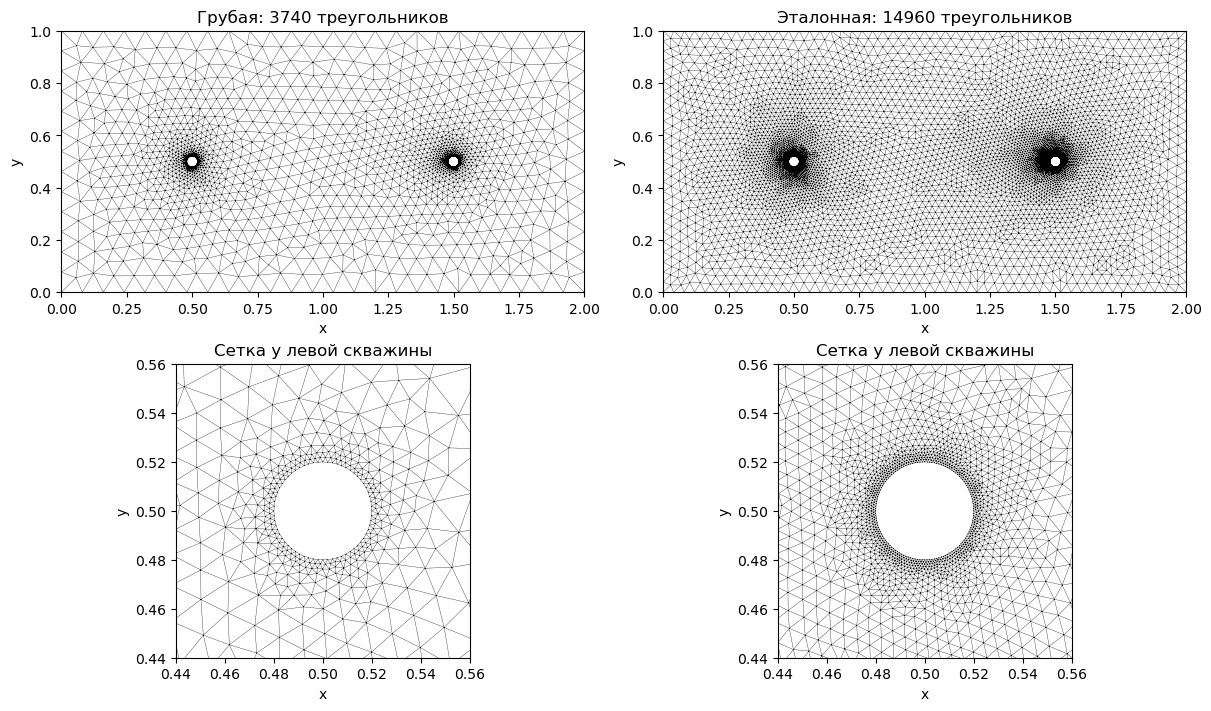

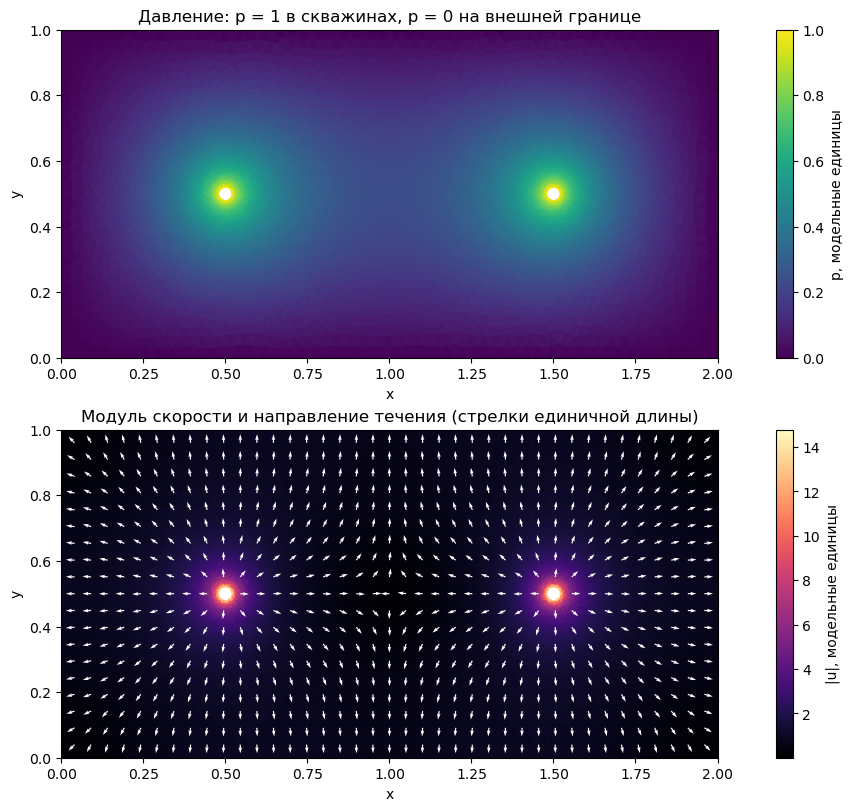

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
for col, (label, data) in enumerate((('Грубая', coarse), ('Эталонная', reference))):
    mesh_i = data['mesh']
    xy = mesh_i.coordinates()
    tri = mtri.Triangulation(xy[:, 0], xy[:, 1], mesh_i.cells())
    for row in (0, 1):
        axes[row, col].triplot(tri, color='black', lw=0.23)
        axes[row, col].set(xlabel='x', ylabel='y', aspect='equal')
    axes[0, col].set(title=f'{label}: {mesh_i.num_cells()} треугольников', xlim=(0, 2), ylim=(0, 1))
    axes[1, col].set(title='Сетка у левой скважины', xlim=(0.44, 0.56), ylim=(0.44, 0.56))
fig.savefig(RESULTS / 'meshes.png', dpi=170)
plt.show()

xy = reference['mesh'].coordinates()
tri = mtri.Triangulation(xy[:, 0], xy[:, 1], reference['mesh'].cells())
fig, axes = plt.subplots(2, 1, figsize=(10, 8), constrained_layout=True)
im = axes[0].tripcolor(tri, facecolors=reference['p_cell'], shading='flat', vmin=0., vmax=1.)
fig.colorbar(im, ax=axes[0], label='p, модельные единицы')
axes[0].set(title='Давление: p = 1 в скважинах, p = 0 на внешней границе')
speed = np.linalg.norm(reference['u_cell'], axis=1)
im = axes[1].tripcolor(tri, facecolors=speed, shading='flat', cmap='magma')
fig.colorbar(im, ax=axes[1], label='|u|, модельные единицы')
gx, gy = np.meshgrid(np.linspace(0.04, 1.96, 39), np.linspace(0.04, 0.96, 19))
sample_xy = np.column_stack((gx.ravel(), gy.ravel()))
mask = np.minimum(np.linalg.norm(sample_xy-(0.5, 0.5), axis=1),
                  np.linalg.norm(sample_xy-(1.5, 0.5), axis=1)) > 0.035
sample_xy = sample_xy[mask]
arrows = np.array([reference['u'](Point(*x)) for x in sample_xy])
arrow_length = np.linalg.norm(arrows, axis=1)
directions = arrows/np.maximum(arrow_length[:, None], 1e-30)
axes[1].quiver(sample_xy[:, 0], sample_xy[:, 1], directions[:, 0], directions[:, 1],
               color='white', angles='xy', scale_units='xy', scale=38., width=0.0018)
axes[1].set(title='Модуль скорости и направление течения (стрелки единичной длины)')
for ax in axes:
    ax.set(xlabel='x', ylabel='y', aspect='equal', xlim=(0, 2), ylim=(0, 1))
fig.savefig(RESULTS / 'solution.png', dpi=170)
plt.show()

### Итог и проверка

Получено ненулевое течение от двух скважин к внешней границе,
соответствующее референсному коду. Нормы разности с эталоном показывают
влияние пространственной аппроксимации давления и скорости.
По двум сеткам нельзя независимо определить порядок сходимости.

Дополнительно проверены: одинаковые площади и границы двух сеток,
дивергенция скорости, суммарный поток, энергетический баланс
$\int_\Omega(\mu/k)|u|^2=-\int_{\partial\Omega}p_D u\cdot n$
и невязка линейной системы. Результаты — в `summary.csv`.
Все величины приведены в модельных единицах референса.

In [6]:
with (RESULTS / 'summary.csv').open('w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['mesh', 'vertices', 'triangles', 'mixed_dofs', 'hmax', 'area',
                     'pressure_min', 'pressure_max', 'velocity_l2',
                     'divergence_l2', 'outer_normal_l2', 'flux_outer', 'flux_left',
                     'flux_right', 'absolute_flux_balance', 'relative_flux_balance',
                     'dissipation', 'boundary_work', 'relative_energy_balance', 'linear_relative_residual'])
    for name, data in (('coarse', coarse), ('reference', reference)):
        mesh_i = data['mesh']
        writer.writerow([name, mesh_i.num_vertices(), mesh_i.num_cells(), data['W'].dim(),
                         mesh_i.hmax(), data['area'], data['p_cell'].min(), data['p_cell'].max(),
                         data['velocity_l2'], data['divergence_l2'],
                         data['outer_normal_l2'], *data['flux'], abs(data['flux'].sum()), data['flux_balance'],
                         data['dissipation'], data['boundary_work'], data['energy_balance'], data['residual']])
        print(f"{name}: p_min = {data['p_cell'].min():.15f}, p_max = {data['p_cell'].max():.15f}, "
              f"|сумма потоков| = {abs(data['flux'].sum()):.3e}")

coarse: p_min = 0.001924752787073, p_max = 0.993228755063407, |сумма потоков| = 8.016e-14
reference: p_min = 0.000499819399668, p_max = 0.996614105518326, |сумма потоков| = 1.064e-12
